### **1. Importing the required packages**

In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Machine Learning Related packages
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

### **2. Reading and Exploring the data**

In [134]:
data = pd.read_csv('data/creditcard.csv')

In [135]:
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,V29,Target
0,0.114697,0.796303,-0.149553,-0.823011,0.878763,-0.553152,0.939259,-0.108502,0.111137,-0.390521,...,-0.335776,-0.807853,-0.055940,-1.025281,-0.369557,0.204653,0.242724,0.085713,0.89,0
1,-0.039318,0.495784,-0.810884,0.546693,1.986257,4.386342,-1.344891,-1.743736,-0.563103,-0.616315,...,-1.377003,-0.072200,-0.197573,1.014807,1.011293,-0.167684,0.113136,0.256836,85.00,0
2,2.275706,-1.531508,-1.021969,-1.602152,-1.220329,-0.462376,-1.196485,-0.147058,-0.950224,1.560463,...,-0.193271,-0.103533,0.150945,-0.811083,-0.197913,-0.128446,0.014197,-0.051289,42.70,0
3,1.940137,-0.357671,-1.210551,0.382523,0.050823,-0.171322,-0.109124,-0.002115,0.869258,-0.001965,...,0.157994,0.650355,0.034206,0.739535,0.223605,-0.195509,-0.012791,-0.056841,29.99,0
4,1.081395,-0.502615,1.075887,-0.543359,-1.472946,-1.065484,-0.443231,-0.143374,1.659826,-1.131238,...,0.224157,0.821209,-0.137223,0.986259,0.563228,-0.574206,0.089673,0.052036,68.00,0


In [136]:
data.shape

(56962, 30)

In [137]:
data.isnull().sum().sum() #prints the total number of missing values column wise

np.int64(0)

In [138]:
data.duplicated().sum()

np.int64(675)

In [139]:
data[data.duplicated()]   #print all the duplicate rows

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,V29,Target
1181,2.010213,0.063667,-1.620606,0.341472,0.368741,-0.586677,0.034489,-0.043750,0.303938,-0.201902,...,-0.301625,-0.820824,0.362729,0.595190,-0.345739,0.150098,-0.066713,-0.040558,1.79,0
1936,1.302378,-0.606529,-0.681986,-1.904603,1.326623,3.436312,-1.145127,0.959147,1.671302,-1.022946,...,-0.064208,-0.080587,-0.072991,1.018136,0.663575,-0.671323,0.096801,0.028697,1.00,0
2530,2.055797,-0.326668,-2.752041,-0.842316,2.463072,3.173856,-0.432126,0.727706,0.608606,-0.075186,...,0.269765,0.844627,0.020675,0.726212,0.366624,-0.398828,0.027735,-0.060282,1.00,0
2878,1.076018,-0.126284,1.320255,1.154681,-0.892714,0.356662,-0.792107,0.396302,0.630048,0.007419,...,0.071098,0.320206,0.055667,0.204490,0.230282,-0.396762,0.077135,0.024214,1.00,0
3301,1.109985,0.368032,-0.061407,1.376844,0.070437,-1.100573,0.610397,-0.487201,0.920589,-0.380884,...,-0.088583,-0.126343,-0.217999,0.358122,0.814626,-0.345815,-0.048111,0.020956,89.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56809,1.886717,-0.517305,-1.351317,-0.141112,0.586967,1.052636,-0.330743,0.353181,0.936002,-0.165864,...,-0.071110,0.074763,0.201228,-1.628444,-0.245710,0.023253,0.014937,-0.081462,20.00,0
56830,1.284143,0.462738,-0.371277,0.825644,0.464456,-0.466731,0.459673,-0.186236,-0.549594,0.204381,...,0.013440,0.084371,-0.246710,-0.325573,0.927623,-0.272459,-0.009998,-0.005489,0.89,0
56865,1.018412,1.036663,-1.689814,1.315476,1.698436,0.528807,0.331715,0.364539,-0.711798,-1.570288,...,-0.040238,0.096172,-0.092549,-1.345664,0.510305,-0.182674,0.107058,0.071818,0.89,0
56893,2.060160,0.018599,-1.072853,0.381576,0.018414,-1.063353,0.240911,-0.365617,0.382032,0.033555,...,-0.275957,-0.600087,0.325765,-0.054364,-0.267467,0.201880,-0.060525,-0.058989,1.29,0


In [140]:
data.drop_duplicates(inplace = True)

In [141]:
data['Target'].value_counts() #check for data imbalance

Target
0    56189
1       98
Name: count, dtype: int64

**What to do to deal with class imbalance:**

1. Upscaling
2. Downscaling
3. Just use tree based algorithms.


In [142]:
56189 / (56189 + 98)

0.9982589230195249

### **Machine Learning Process**

In [143]:
X = data.drop(columns = 'Target')
y = data['Target']

In [144]:
#train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 100)

### **Apply the Decision Tree Classifier**

In [145]:
dec_tree = DecisionTreeClassifier(criterion='gini', max_depth=16)
dec_tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=16)

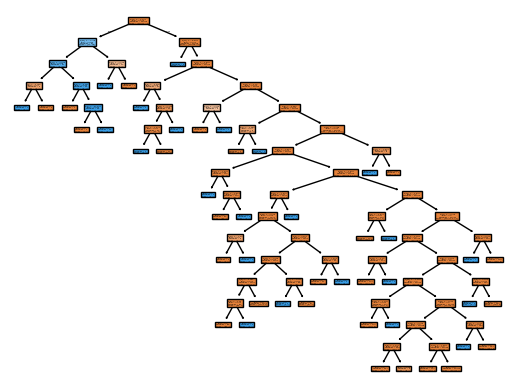

In [146]:
from sklearn import tree

final_tree = tree.plot_tree(dec_tree, filled = True)

In [147]:
dec_tree.get_depth()

16

In [148]:
y_pred = dec_tree.predict(X_test)

In [149]:
accuracy_score(y_test, y_pred) #use it only if your data is balanced

0.9992005684846331

In [150]:
roc_auc_score(y_test, y_pred) #use this metric instead of accuracy_score when the data is imbalanced

np.float64(0.874822032390105)

#### **Check for overfitting issues in the decision tree**

In [151]:
#we need to check for the training accuracy
y_pred_train = dec_tree.predict(X_train)

In [152]:
roc_auc_score(y_train, y_pred_train)

np.float64(0.9871794871794872)

### **Other performance metrics**

In [153]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[11234,     4],
       [    5,    15]])

In [154]:
TN, FP, FN, TP = cm.ravel()

In [155]:
print(f'True Negatives: {TN}')

True Negatives: 11234


In [156]:
precision_score(y_test, y_pred)

np.float64(0.7894736842105263)

In [157]:
recall_score(y_test, y_pred)

np.float64(0.75)

In [158]:
f1_score(y_test, y_pred)

np.float64(0.7692307692307693)

### Performance Metrics used in Classification Models

1. **`Confusion Matrix`** : A confusion matrix is a table that summarizes the performance of a classification model by showing the true positives (TP), true negatives (TN), false positives (FP), and false negatives (FN).

    - **`When to Use`**: The confusion matrix is useful for understanding the types of errors the model is making and for calculating other metrics like precision, recall, and specificity.
    
![confusion_matrix](https://builtin.com/sites/www.builtin.com/files/styles/ckeditor_optimize/public/inline-images/8_confusion-matrix-python.jpg)

---

2. **`Precision Score`** : Precision is important when the cost of false positives is high, so false positives must be reduced.
    - `For example` :
        - In spam detection, a high precision ensures that most of the emails marked as spam are indeed spam and genuine emails are not marked as spam since it can be a serious problem.
        - In financial fraud detection system, it might prioritize high precision – minimizing false positives (wrongly declined transactions) to avoid inconveniencing customers.
        - While classifying whether or not a bank customer is a loan defaulter, it is desirable to have high precision since the bank wouldn’t want to lose customers who were denied a loan based on the model’s prediction that they would be defaulters.

---

3. **`Recall Score/Sensitivity`** : Recall is crucial when the cost of false negatives is high and we need to eliminate false negatives as much as possible.
    - `For Example`:
        - In medical diagnosis, a high recall is crucial since it ensures that most of the actual positive cases (e.g., diseases) are identified. False Negative would mean that we classified a patient as a healthy person which would be fatal.

---

4. **`Accuracy Score`** : It is suitable to use when the classes in the dataset are balanced. It provides a straightforward measure of overall correctness. However, it can be misleading in cases of class imbalance, where one class significantly outnumbers the other.

    - Using accuracy as a defining metric for our model makes sense intuitively, but more often than not, it is advisable to use Precision and Recall too. There might be other situations where our accuracy is very high, but our precision or recall is low. Ideally, for our model, we would like to avoid any situations where the patient has heart disease, but our model classifies as him not having it, i.e., aim for high recall.

    - On the other hand, for the cases where the patient is not suffering from heart disease and our model predicts the opposite, we would also like to avoid treating a patient with no heart disease (crucial when the input parameters could indicate a different ailment, but we end up treating him/her for a heart ailment).

    - Although we do aim for high precision and high recall value, achieving both at the same time is not possible. For example, if we change the model to one giving us a high recall, we might detect all the patients who actually have heart disease, but we might end up giving treatments to many patients who don’t suffer from it.

    - Similarly, suppose we aim for high precision to avoid giving any wrong and unrequired treatment. In that case, we end up getting a lot of patients who actually have heart disease going without any treatment.

---

5. **`F1 Score`** : We saw above that there is a trade-off between recall and precision-score. When we try to increase one, the other one starts to reduce. But sometime both the score are important.
    - `Ex`:  if the doctor informs us that the patients who were incorrectly classified as suffering from heart disease are equally important since they could be indicative of some other ailment, then we would aim for not only a high recall but a high precision as well.
    
---


6. **`ROC_AUC Score`** - Used commonly with imbalanced data.

---

7. **`Specificity`** : Specificity is a performance metric used in classification models, particularly in binary classification. It is also known as the true negative rate. Specificity measures the proportion of actual negative cases that are correctly identified by the model. This metric tells us how well the model is at identifying negative instances.
    - `Ex` : In medical testing, a high specificity is important when a false positive result could lead to unnecessary stress, further invasive testing, or treatment. For example, in cancer screening, a test with high specificity ensures that healthy individuals are not incorrectly diagnosed with cancer, avoiding unnecessary biopsies or treatments

## Heart Disease Data 

In [159]:
df = pd.read_csv('data/heart.csv')

In [160]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [162]:
df.shape

(303, 14)

In [163]:
df.isnull().sum().sum() #prints the total number of missing values column wise


np.int64(0)

In [164]:
df.duplicated().sum()

np.int64(1)

In [165]:
df.drop_duplicates(inplace=True)

In [166]:
df.target.value_counts()

target
1    164
0    138
Name: count, dtype: int64

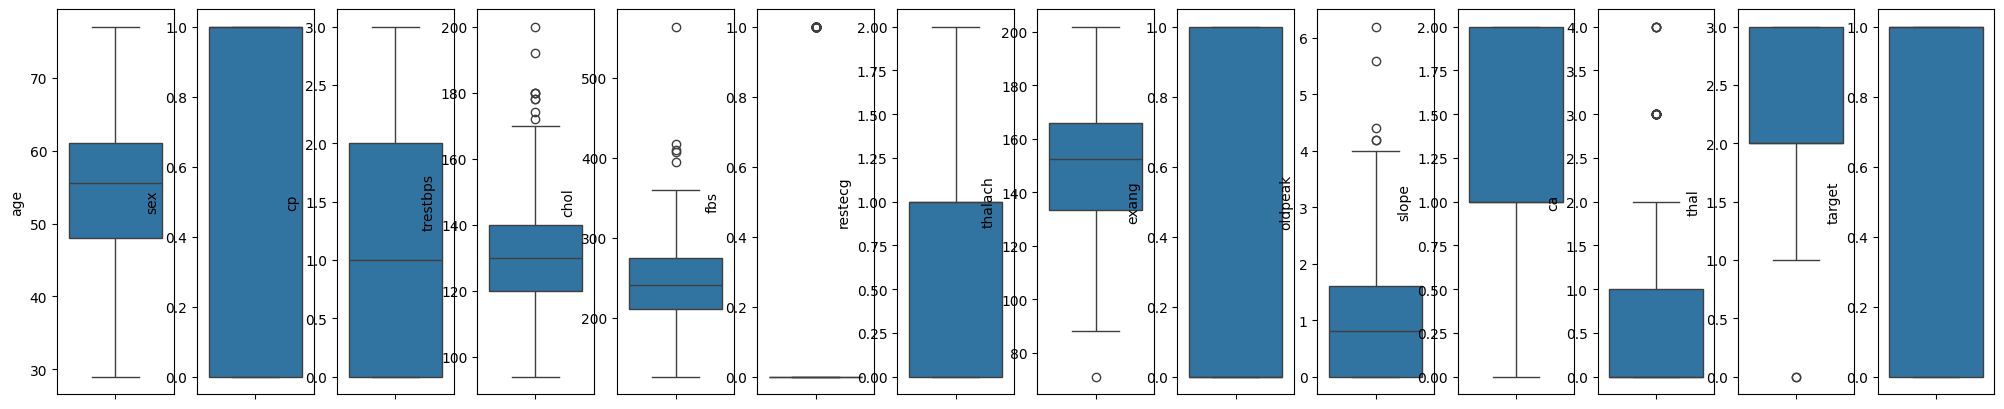

In [167]:
features = df.select_dtypes(include=["number"]).columns.tolist()
features_plot = [i for i in features if i  not in  ['target', 'sex']]

fig, axes = plt.subplots(1, len(features), figsize =(25,5))


for col, ax in zip(features, axes):
    if df[col].dtype != object:
        sns.boxplot(y = df[col], ax= ax)

In [168]:
X = df.drop(columns='target')
y = df.target.values

In [169]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, 
                                                    random_state=42)

In [170]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=5)

In [171]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5)

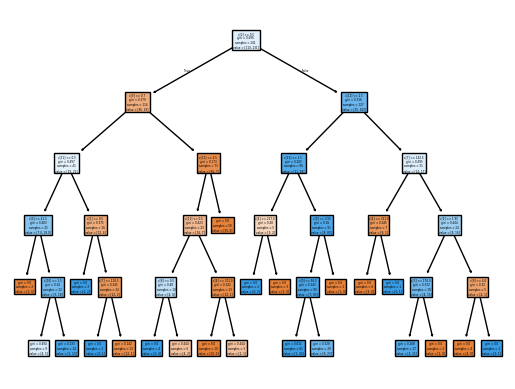

In [172]:
from sklearn import tree

final_tree = tree.plot_tree(clf, filled = True)

2.3.2


/home/amandip/ML_env/ML_env_1/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names


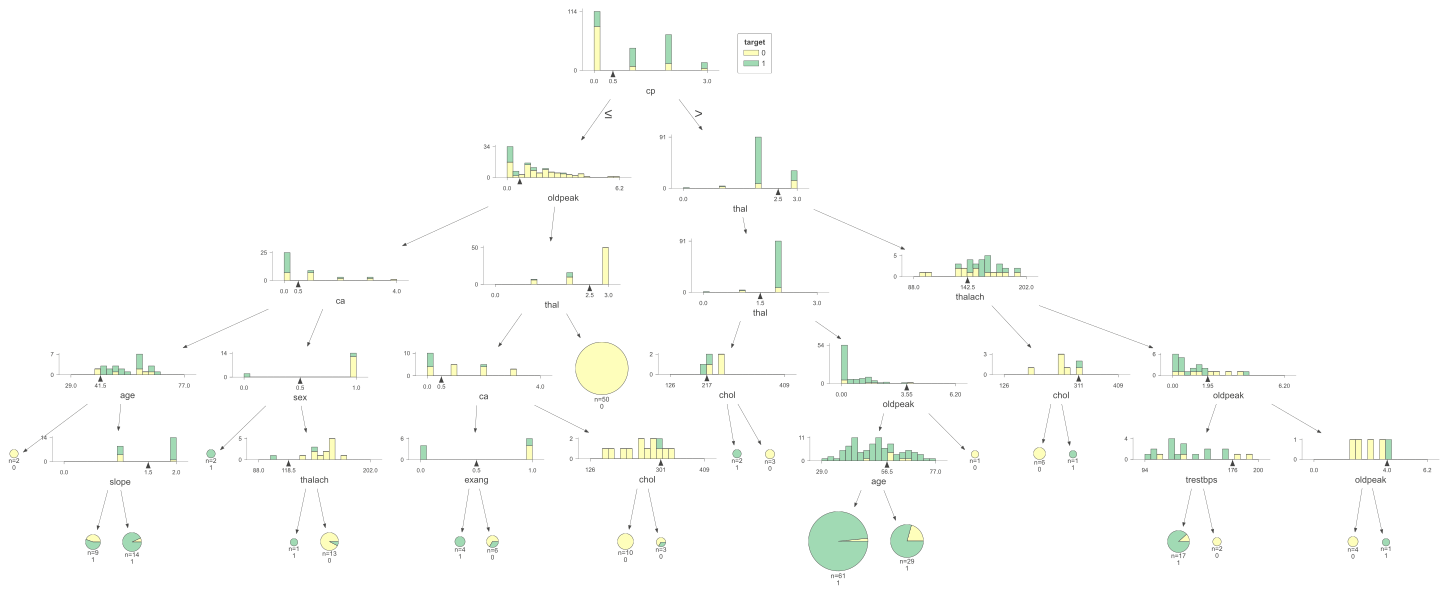

In [173]:
# cool way to look at the tree

import dtreeviz
print(dtreeviz.__version__)

from IPython.display import display

features = df.drop(columns="target").columns.tolist()

viz_model = dtreeviz.model(
    clf,
    X_train=X_train,
    y_train=y_train,
    feature_names=features,
    target_name="target",
    class_names=["0", "1"]
)

viz = viz_model.view()
display(viz)


In [174]:
y_pred = clf.predict(X_test)
y_pred_train = clf.predict(X_train)


In [175]:
print(f'Test acc: {accuracy_score(y_pred, y_test)}')
print(f'Train acc: {accuracy_score(y_pred_train, y_train)}')


Test acc: 0.8032786885245902
Train acc: 0.9253112033195021


## Test Data

In [176]:
df = pd.read_csv('data/Loan_default.csv')


In [177]:
df.shape

(255347, 18)

In [178]:
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

In [180]:
# drop name 
df.drop(columns='LoanID')

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [181]:
df.duplicated().sum()

np.int64(0)

In [182]:
df.isnull().sum().sum()

np.int64(0)

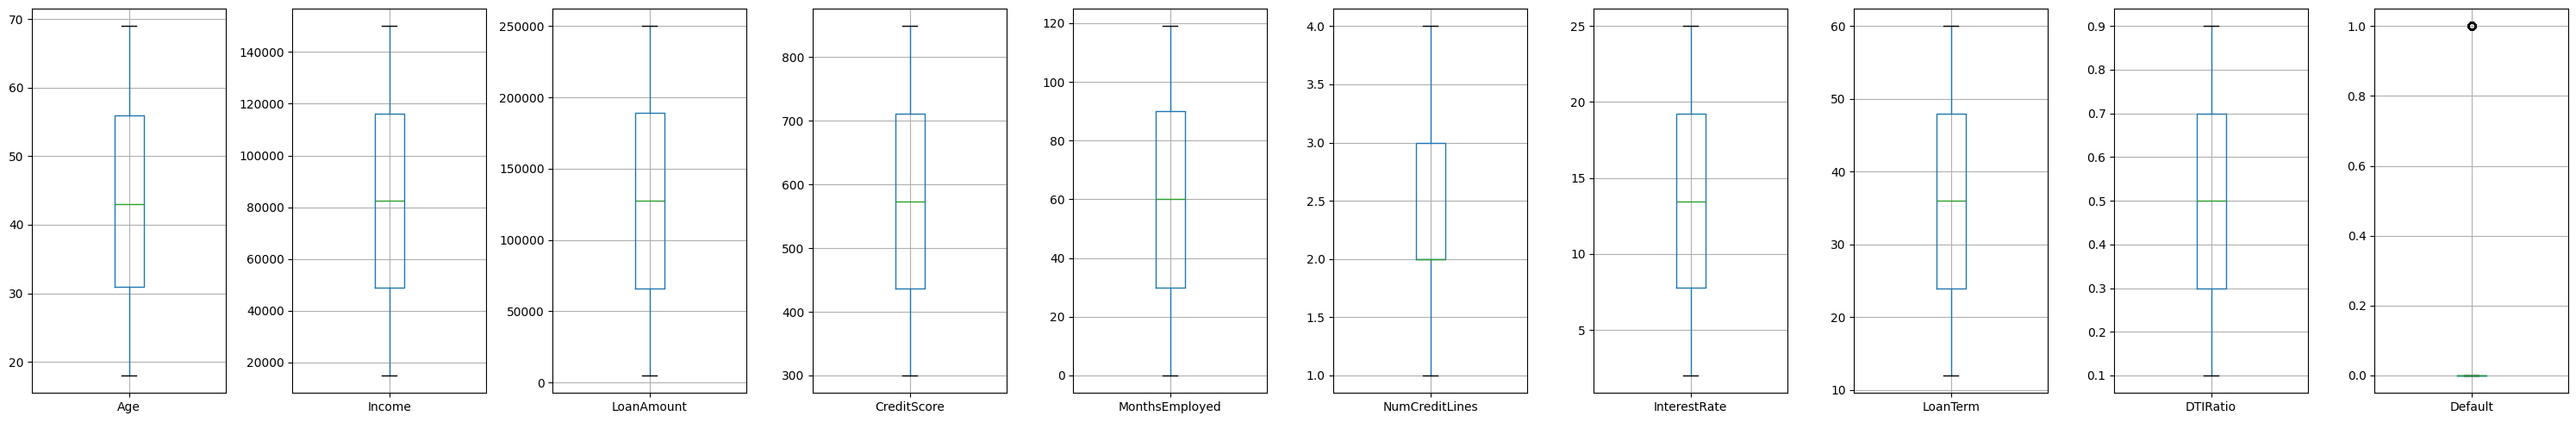

In [183]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

fig, axes = plt.subplots(1, len(numeric_columns), figsize=(30, 5))
for ax, col in zip(axes, numeric_columns):
    df.boxplot(column=col, ax=ax) 

plt.tight_layout()
plt.show()

In [184]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

object_columns = df.select_dtypes(include=['object']).columns.to_numpy()
print(object_columns)

for col in object_columns:
    df[col] = le.fit_transform(df[col])
df.info()

['LoanID' 'Education' 'EmploymentType' 'MaritalStatus' 'HasMortgage'
 'HasDependents' 'LoanPurpose' 'HasCoSigner']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  int64  
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  int64  
 11  EmploymentType  255347 non-null  int64  
 12  MaritalStatus   255347 non-null  int64  
 13  HasMortgage     255347 non-null  int64  
 14  HasDependents   255347 non-null  

In [185]:
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,128027,56,85994,50587,520,80,4,15.23,36,0.44,0,0,0,1,1,4,1,0
1,125442,69,50432,124440,458,15,1,4.81,60,0.68,2,0,1,0,0,4,1,0
2,85333,46,84208,129188,451,26,3,21.17,24,0.31,2,3,0,1,1,0,0,1
3,220129,32,31713,44799,743,0,3,7.07,24,0.23,1,0,1,0,0,1,0,0
4,105746,60,20437,9139,633,8,4,6.51,48,0.73,0,3,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,58985,19,37979,210682,541,109,4,14.11,12,0.85,0,0,1,0,0,4,0,0
255343,65642,32,51953,189899,511,14,2,11.55,24,0.21,1,1,0,0,0,3,0,1
255344,239303,56,84820,208294,597,70,3,5.29,60,0.50,1,2,1,1,1,0,1,0
255345,136634,42,85109,60575,809,40,1,20.90,48,0.44,1,1,2,1,1,4,0,0


In [186]:
df.Default.value_counts()

Default
0    225694
1     29653
Name: count, dtype: int64

In [187]:
X = df.drop(columns='Default')
y = df.Default

In [188]:
X_train, X_test, y_train, y_test = train_test_split(X, y , stratify=y, random_state=42)

In [189]:
clf = DecisionTreeClassifier(criterion='gini', 
                             max_depth=5)


In [190]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5)

2.3.2


/home/amandip/ML_env/ML_env_1/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names


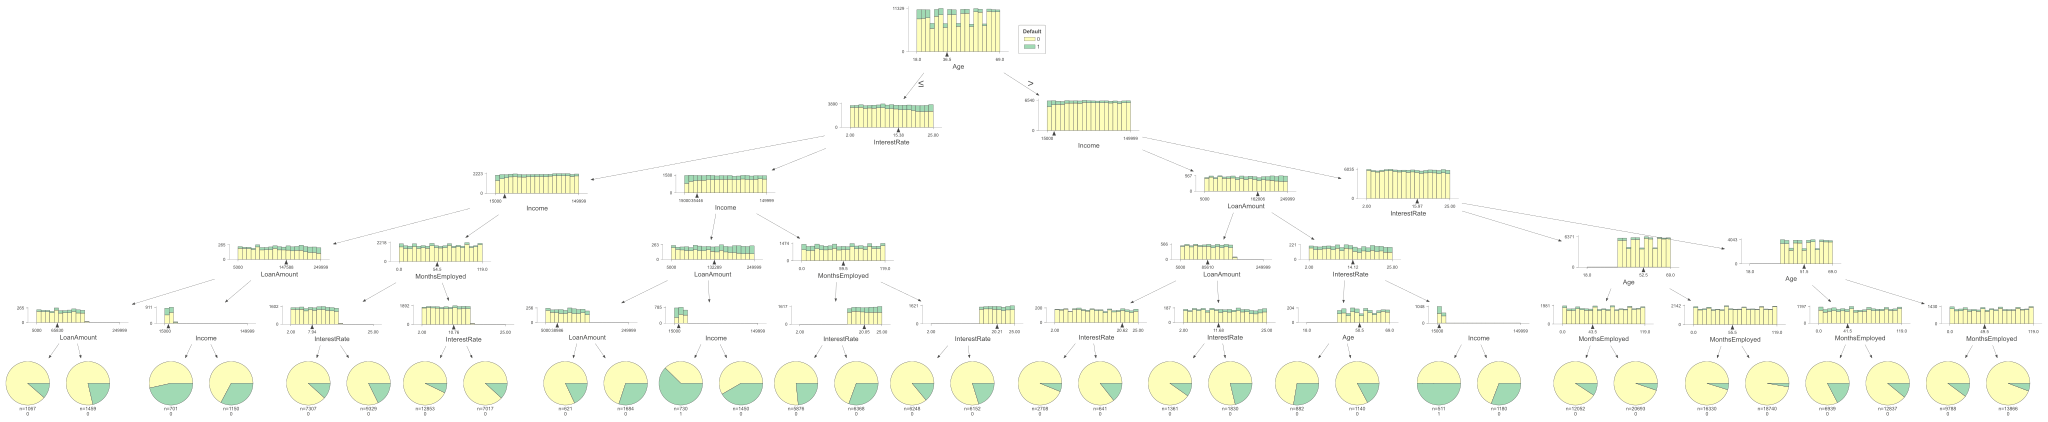

In [191]:
import dtreeviz
print(dtreeviz.__version__)

from IPython.display import display

features = df.drop(columns="Default").columns.tolist()

viz_model = dtreeviz.model(
    clf,
    X_train=X_train,
    y_train=y_train,
    feature_names=features,
    target_name="Default",
    class_names=["0", "1"]
)

viz = viz_model.view()
display(viz)


In [192]:
y_pred = clf.predict(X_test)
y_pred_train = clf.predict(X_train)

In [193]:
print(f'Test acc: {accuracy_score(y_pred, y_test)}')
print(f'Train acc: {accuracy_score(y_pred_train, y_train)}')


Test acc: 0.885003994548616
Train acc: 0.8848154143386768
